[nltk_data] Downloading package wordnet to /Users/sakis/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


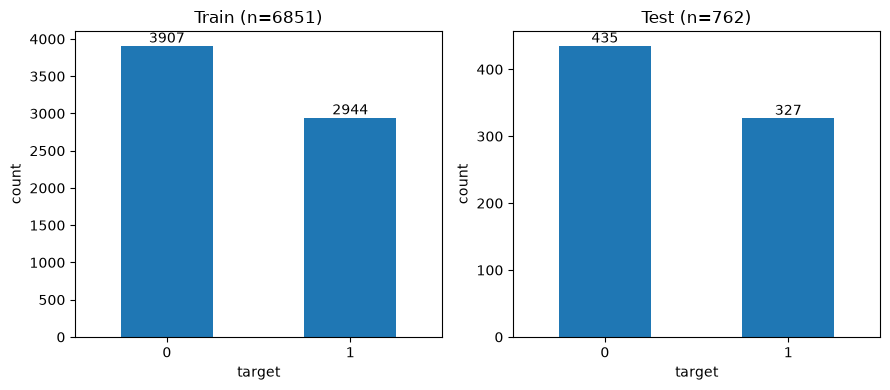

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from techniques import (removeEmoticons, removeUnicode, replaceAtUser, replaceURL, 
                        replaceElongated, replaceMultiExclamationMark, replaceMultiQuestionMark,
                        removeHashtagInFrontOfWord, replaceSlang)
import nltk

# used by techniques
nltk.download("wordnet")

# use various functions to make the text a bit more consistent between
# the different tweets (e.g. fix slang), and remove unncessary 
# noise (user references, urls, emoticons, etc)
text_fixes = [
    removeEmoticons,
    removeUnicode, 
    replaceAtUser, 
    replaceURL, 
    replaceSlang,
    replaceElongated, 
    replaceMultiExclamationMark, 
    replaceMultiQuestionMark,
    removeHashtagInFrontOfWord
]

train_df = pd.read_csv("train.csv")
#test_df = pd.read_csv("test.csv")


#Q3: Fix the text before concactenating
for fix in text_fixes:
    train_df["text"] = train_df["text"].apply(fix)

#Q2: drop unnecessary characteristics and combine keyword + text to a new characteristic "inputs":
train_df = train_df.drop(columns=["id", "location"])
train_df["keyword"] = train_df["keyword"].fillna("null")
train_df["inputs"] = train_df["keyword"] + " " + train_df["text"]

test_size = 0.1
y = train_df["target"]
x_train, x_test, y_train, y_test = train_test_split(train_df, y, test_size=test_size, stratify=y, random_state=0)


# counts per class
train_counts = y_train.value_counts().sort_index()
test_counts = y_test.value_counts().sort_index()
# print(train_counts)
# print("\n\n")
# print(test_counts)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4))

train_counts.plot(kind="bar", ax=ax1, rot=0, title=f"Train (n={len(y_train)})")
ax1.set_xlabel("target")
ax1.set_ylabel("count")
ax1.bar_label(ax1.containers[0])

test_counts.plot(kind="bar", ax=ax2, rot=0, title=f"Test (n={len(y_test)})")
ax2.set_xlabel("target")
ax2.set_ylabel("count")
ax2.bar_label(ax2.containers[0])

plt.tight_layout()
plt.show()

In [2]:
# We observer that the classes are fairly balanced

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

# q4:
x = train_df["inputs"].to_numpy()
y = train_df["target"].to_numpy()
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=test_size, stratify=y, random_state=0)

# q5:
vectorizer = TfidfVectorizer()
x_train_tfidf = vectorizer.fit_transform(x_train)
x_test_tfidf = vectorizer.transform(x_test)

# q6:
gnb = GaussianNB()
gnb.fit(x_train_tfidf.toarray(), y_train)

y_pred = gnb.predict(x_test_tfidf.toarray())
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.6246719160104987
